# Astronomy Campus final plotting notebook

This notebook reproduces the three matched figures:
1. Background Counts Contour
2. Background Sky Radiance Contour
3. QBER Contour

It assumes the original `lightsoff1truncated.xls` and `lightson1truncated.xls` files are in the same folder as the notebook.


In [1]:
# If needed, run this once:
# %pip install numpy pandas matplotlib scipy xlrd pillow

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle
from matplotlib.colors import LogNorm, Normalize
from matplotlib.ticker import FixedLocator, FuncFormatter
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from PIL import Image


In [3]:
# -----------------------------
# Input files
# -----------------------------
DATA_DIR = Path("D:/PhD Thesis Writing/astrocampusdata")

LIGHTS_OFF_FILE = DATA_DIR / "lightsoff1truncated.xls"
LIGHTS_ON_FILE = DATA_DIR / "lightson1truncated.xls"

OUTPUT_DIR = Path("qkd_final_figures")
OUTPUT_DIR.mkdir(exist_ok=True)

def load_original_xls(path):
    return pd.read_excel(
        path,
        header=None,
        names=["counts_cps", "scan_deg", "orientation_deg"],
        engine="xlrd",
    )

data = {
    "lights_off": load_original_xls(LIGHTS_OFF_FILE),
    "lights_on": load_original_xls(LIGHTS_ON_FILE),
}


In [125]:
# -----------------------------
# Parameters
# -----------------------------
DARK_CPS = 208.0

APERTURE_DIAMETER_M = 0.024
FOV_HALF_ANGLE_RAD = 458e-6
FILTER_CENTRE_NM = 830.0
FILTER_BANDWIDTH_NM = 10.0
DETECTOR_PDE = 0.45

SIGNAL_CPS = 20.0
F_REP_HZ = 2e6
TIMING_WINDOW_S = 1e-9
E_SIG = 0.01

CMAP_NAME = "magma"
N_LEVELS = 30
INTERPOLATION_GRID = 500
SMOOTHING_SIGMA = 6

plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=14)

MAIN_TITLE_SIZE = 24
SUBPLOT_TITLE_SIZE = 16
SUBPLOT_PAD = -6

FIGSIZE = (14.5, 6.8)
GRIDSPEC = dict(
    nrows=1,
    ncols=5,
    width_ratios=[1, -0.07, 1, 0.02, 0.035],
    left=0.05,
    right=0.92,
    top=0.83,
    bottom=0.10,
    wspace=-0.16,
)

APERTURE_AREA_M2 = np.pi * (APERTURE_DIAMETER_M / 2)**2
SOLID_ANGLE_SR = np.pi * FOV_HALF_ANGLE_RAD**2


In [65]:
# -----------------------------
# Derived quantities
# -----------------------------
def add_derived_quantities(df):
    out = df.copy()

    out["sky_counts_cps"] = np.clip(
        out["counts_cps"] - DARK_CPS,
        0,
        None,
    )

    out["accepted_noise_cps"] = (
        out["counts_cps"]
        * F_REP_HZ
        * TIMING_WINDOW_S
    )

    out["qber_pct"] = (
        (
            E_SIG * SIGNAL_CPS
            + 0.5 * out["accepted_noise_cps"]
        )
        /
        (
            SIGNAL_CPS
            + out["accepted_noise_cps"]
        )
        * 100.0
    )

    out["radiance_ph"] = (
        out["sky_counts_cps"]
        /
        (
            APERTURE_AREA_M2
            * SOLID_ANGLE_SR
            * FILTER_BANDWIDTH_NM
            * DETECTOR_PDE
        )
    )

    # Rescale only for cleaner colour-bar tick labels.
    out["radiance_div1e9"] = out["radiance_ph"] / 1e9

    return out

data = {
    name: add_derived_quantities(df)
    for name, df in data.items()
}


In [67]:
# -----------------------------
# Sky projection + interpolation
# -----------------------------
def sky_xy(df):
    t = np.deg2rad(df["scan_deg"].to_numpy() - 90.0)
    a = np.deg2rad(df["orientation_deg"].to_numpy())

    x = np.sin(t) * np.sin(a)
    y = np.sin(t) * np.cos(a)

    return x, y


def interp_sky(df, value_col, n=INTERPOLATION_GRID):
    x, y = sky_xy(df)
    z = df[value_col].to_numpy()

    gx = np.linspace(-1.0, 1.0, n)
    gy = np.linspace(-1.0, 1.0, n)
    X, Y = np.meshgrid(gx, gy)

    mask = X**2 + Y**2 <= 1.0
    points = np.column_stack([x, y])

    Z_linear = griddata(points, z, (X, Y), method="linear")
    Z_nearest = griddata(points, z, (X, Y), method="nearest")
    Z = np.where(np.isnan(Z_linear), Z_nearest, Z_linear)

    Z_masked = np.where(mask, Z, 0.0)
    W = mask.astype(float)

    Z_smooth = gaussian_filter(
        Z_masked,
        sigma=SMOOTHING_SIGMA,
    )
    W_smooth = gaussian_filter(
        W,
        sigma=SMOOTHING_SIGMA,
    )

    Z = Z_smooth / np.maximum(W_smooth, 1e-12)

    Z = np.clip(
        Z,
        np.nanmin(z),
        np.nanmax(z),
    )

    Z[~mask] = np.nan

    return X, Y, Z


In [69]:
# -----------------------------
# Sky-axis styling
# -----------------------------
def decorate_sky_axes(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            1.0,
            fill=False,
            linewidth=1.0,
            edgecolor="black",
        )
    )

    # 60 degree elevation circle
    ax.add_patch(
        Circle(
            (0, 0),
            np.sin(np.deg2rad(30)),
            fill=False,
            linewidth=0.8,
            linestyle="--",
            edgecolor="white",
            alpha=0.95,
        )
    )

    # 30 degree elevation circle
    ax.add_patch(
        Circle(
            (0, 0),
            np.sin(np.deg2rad(60)),
            fill=False,
            linewidth=0.8,
            linestyle="--",
            edgecolor="white",
            alpha=0.95,
        )
    )

    ax.text(0, 1.035, "N", ha="center", va="bottom", fontsize=15)
    ax.text(1.06, 0, "E", ha="left", va="center", fontsize=15)
    ax.text(0, -1.06, "S", ha="center", va="top", fontsize=15)
    ax.text(-1.06, 0, "W", ha="right", va="center", fontsize=15)

    ax.text(
        0,
        np.sin(np.deg2rad(60)) + 0.015,
        "30°",
        ha="center",
        va="bottom",
        fontsize=10,
        color="white",
    )

    ax.text(
        0,
        np.sin(np.deg2rad(30)) + 0.015,
        "60°",
        ha="center",
        va="bottom",
        fontsize=10,
        color="white",
    )

    ax.set_aspect("equal")
    ax.set_xlim(-1.08, 1.08)
    ax.set_ylim(-1.08, 1.08)
    ax.axis("off")


In [113]:
# -----------------------------
# Shared figure setup
# -----------------------------
def int_formatter(x, pos):
    return f"{int(round(x))}"


def setup_figure():
    fig = plt.figure(figsize=FIGSIZE)

    gs = fig.add_gridspec(
        **GRIDSPEC
    )

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 2])
    cax = fig.add_subplot(gs[0, 4])

    return fig, ax1, ax2, cax


def finalize_figure(fig, ax1, ax2, title, output_path):
    center_x = (
        ax1.get_position().x0
        + ax2.get_position().x1
    ) / 2

    fig.suptitle(
        title,
        x=center_x,
        y=0.975,
        fontsize=MAIN_TITLE_SIZE,
    )

    # Important: no bbox_inches="tight".
    # This keeps all three figures at exactly the same pixel dimensions.
    fig.savefig(
        output_path,
        dpi=220,
    )

    plt.show()
    plt.close(fig)


In [73]:
# -----------------------------
# Counts / sky-radiance pair
# -----------------------------
def draw_pair_log(
    value_col,
    figure_title,
    colorbar_label,
    output_path,
    ticks,
    cbar_top_text=None,
):
    vmin = min(
        data["lights_off"][value_col].min(),
        data["lights_on"][value_col].min(),
    )

    vmax = max(
        data["lights_off"][value_col].max(),
        data["lights_on"][value_col].max(),
    )

    vmin = max(vmin, 1e-12)

    levels = np.geomspace(
        vmin,
        vmax,
        N_LEVELS,
    )

    norm = LogNorm(
        vmin=vmin,
        vmax=vmax,
    )

    fig, ax1, ax2, cax = setup_figure()

    contour = None

    for ax, state, subtitle in zip(
        [ax1, ax2],
        ["lights_off", "lights_on"],
        ["a)", "b)"],
    ):
        X, Y, Z = interp_sky(
            data[state],
            value_col,
        )

        contour = ax.contourf(
            X,
            Y,
            Z,
            levels=levels,
            cmap=CMAP_NAME,
            norm=norm,
            extend="both",
        )

        ax.contour(
            X,
            Y,
            Z,
            levels=8,
            colors="white",
            linewidths=0.18,
            alpha=0.22,
        )

        decorate_sky_axes(ax)

        ax.set_title(
            subtitle,
            pad=SUBPLOT_PAD,
            fontsize=SUBPLOT_TITLE_SIZE,
            loc="left",
        )

    cb = fig.colorbar(
        contour,
        cax=cax,
    )

    cb.set_label(
        colorbar_label,
    )

    cb.ax.tick_params(
        labelsize=10,
    )

    cb.locator = FixedLocator(
        ticks
    )

    cb.formatter = FuncFormatter(
        int_formatter
    )

    cb.update_ticks()

    if cbar_top_text is not None:
        cb.ax.set_title(
            cbar_top_text,
            fontsize=10,
            pad=4,
        )

    finalize_figure(
        fig,
        ax1,
        ax2,
        figure_title,
        output_path,
    )


In [75]:
# -----------------------------
# QBER pair
# -----------------------------
def draw_pair_qber(
    figure_title,
    colorbar_label,
    output_path,
):
    vmin = 1.0
    vmax = 11.0

    levels = np.linspace(
        vmin,
        vmax,
        N_LEVELS,
    )

    norm = Normalize(
        vmin=vmin,
        vmax=vmax,
    )

    fig, ax1, ax2, cax = setup_figure()

    contour = None

    for ax, state, subtitle in zip(
        [ax1, ax2],
        ["lights_off", "lights_on"],
        ["a)", "b)"],
    ):
        X, Y, Z = interp_sky(
            data[state],
            "qber_pct",
        )

        contour = ax.contourf(
            X,
            Y,
            Z,
            levels=levels,
            cmap=CMAP_NAME,
            norm=norm,
            extend="max",
        )

        ax.contour(
            X,
            Y,
            Z,
            levels=8,
            colors="white",
            linewidths=0.16,
            alpha=0.18,
        )

        decorate_sky_axes(ax)

        ax.set_title(
            subtitle,
            pad=SUBPLOT_PAD,
            fontsize=SUBPLOT_TITLE_SIZE,
            loc="left",
        )

    cb = fig.colorbar(
        contour,
        cax=cax,
        extend="max",
    )

    # Added padding so QBER (%) sits as far from the bar as
    # the sky-radiance title does visually.
    cb.set_label(
        colorbar_label,
        labelpad=22,
    )

    cb.set_ticks(
        np.arange(1, 12, 1)
    )

    cb.ax.tick_params(
        labelsize=10,
    )

    finalize_figure(
        fig,
        ax1,
        ax2,
        figure_title,
        output_path,
    )


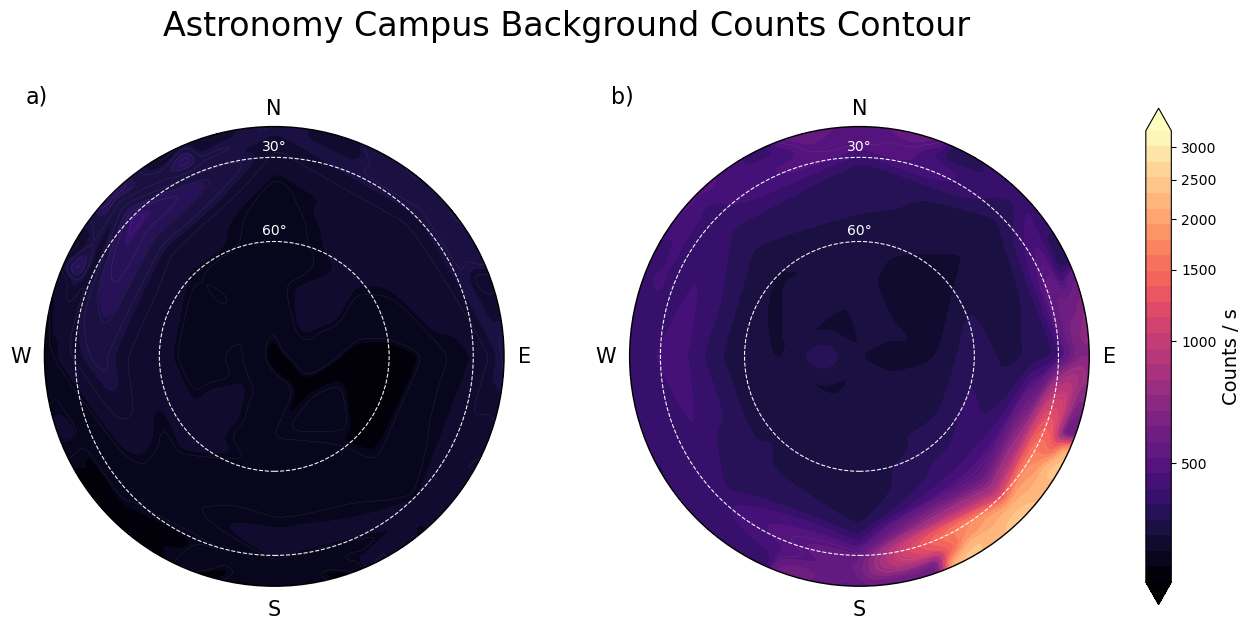

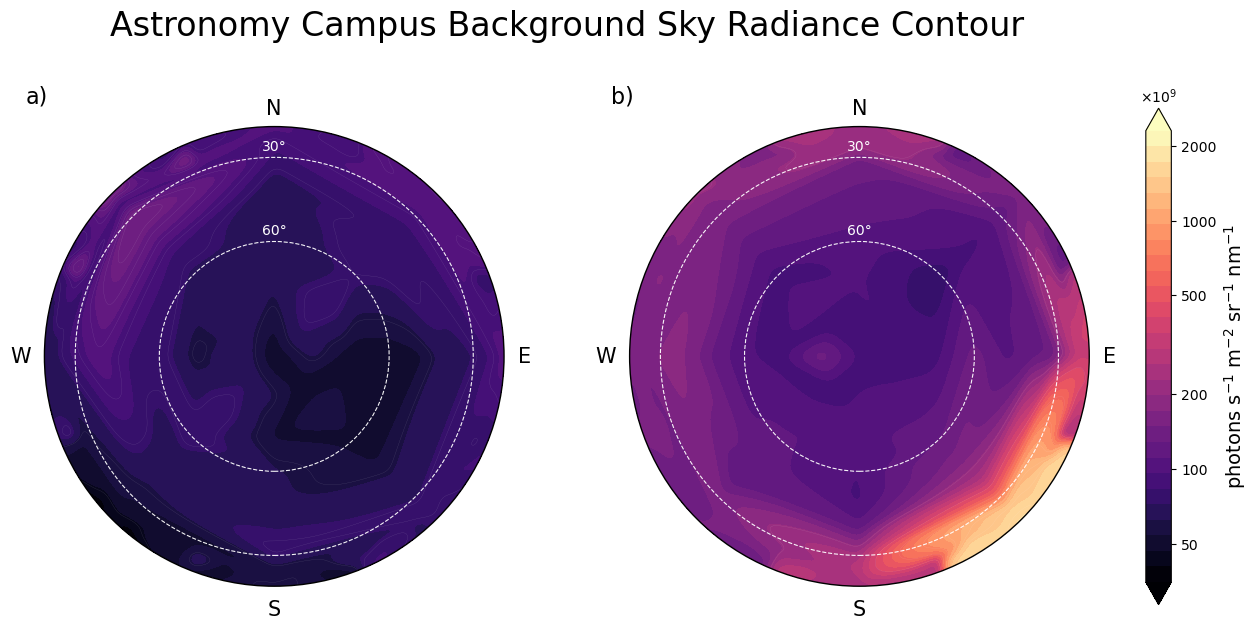

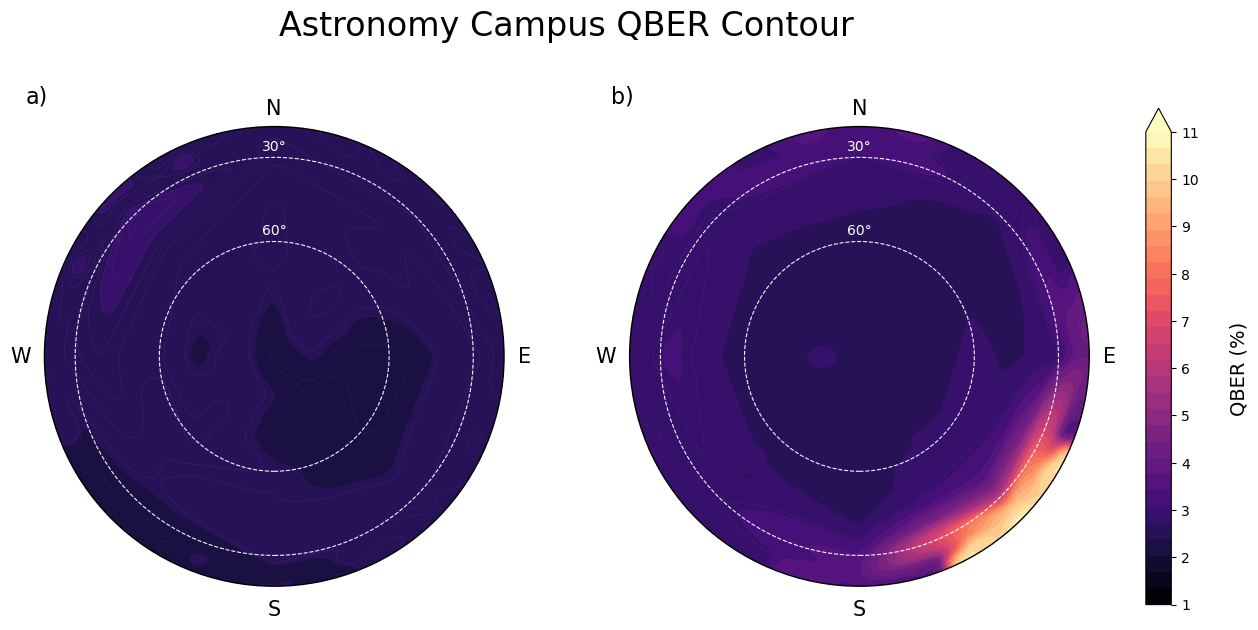

qkd_final_figures\C2_counts_contour.pdf
qkd_final_figures\C2_sky_radiance_contour.pdf
qkd_final_figures\C2_qber_contour.pdf


In [127]:
# -----------------------------
# Generate final figures
# -----------------------------
counts_path = OUTPUT_DIR / "C2_counts_contour.pdf"
radiance_path = OUTPUT_DIR / "C2_sky_radiance_contour.pdf"
qber_path = OUTPUT_DIR / "C2_qber_contour.pdf"

draw_pair_log(
    value_col="counts_cps",
    figure_title="Astronomy Campus Background Counts Contour",
    colorbar_label="Counts / s",
    output_path=counts_path,
    ticks=np.linspace(500, 3000, 6),
)

draw_pair_log(
    value_col="radiance_div1e9",
    figure_title="Astronomy Campus Background Sky Radiance Contour",
    colorbar_label=r"photons s$^{-1}$ m$^{-2}$ sr$^{-1}$ nm$^{-1}$",
    output_path=radiance_path,
    ticks=[50, 100, 200, 500, 1000, 2000],
    cbar_top_text=r"$\times 10^{9}$",
)

draw_pair_qber(
    figure_title="Astronomy Campus QBER Contour",
    colorbar_label="QBER (%)",
    output_path=qber_path,
)

print(counts_path)
print(radiance_path)
print(qber_path)


In [59]:
# -----------------------------
# Verify identical dimensions
# -----------------------------
for path in [
    counts_path,
    radiance_path,
    qber_path,
]:
    image = Image.open(path)
    print(path.name, image.size)


UnidentifiedImageError: cannot identify image file 'C:\\Users\\Ry\\qkd_final_figures\\C2_counts_contour.pdf'